# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm


## Task 1 — Select and download a medical image dataset from Kaggle


In [12]:
%pip -q install kagglehub scikit-image scikit-learn pandas matplotlib seaborn pillow

In [13]:
import os, random, time, warnings, pathlib, glob, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import kagglehub
try:
    DATASET_PATH = kagglehub.dataset_download("andrewmvd/medical-mnist")
    print("Dataset downloaded to:", DATASET_PATH)
except Exception as e:
    print("Direct Kaggle download did not succeed.")
    print("If authentication is required: visit https://www.kaggle.com/settings, create an API token,")
    print("then upload kaggle.json into this notebook session and rerun this cell.")
    try:
        from google.colab import files
        uploaded = files.upload()
        if "kaggle.json" in uploaded:
            os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
            shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
            os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
            DATASET_PATH = kagglehub.dataset_download("andrewmvd/medical-mnist")
            print("Dataset downloaded to:", DATASET_PATH)
        else:
            raise RuntimeError("kaggle.json was not uploaded.")
    except Exception as fallback_error:
        raise RuntimeError(
            "Could not download the Kaggle dataset. Ensure internet access and, if requested, configure kaggle.json. "
            f"Original error: {e}; fallback error: {fallback_error}"
        )

Using Colab cache for faster access to the 'medical-mnist' dataset.
Dataset downloaded to: /kaggle/input/medical-mnist


## Task 2 — Preprocess images and create fixed train, validation, and test sets
Images are converted to grayscale and resized to **128 × 128**. To limit runtime, the code samples at most a fixed number per class. The same stratified split indices are used by both models.

Detected class-folder root: /kaggle/input/medical-mnist
Classes: {0: 'AbdomenCT', 1: 'BreastMRI', 2: 'CXR', 3: 'ChestCT', 4: 'Hand', 5: 'HeadCT'}
Train: 1050 Validation: 225 Test: 225
Train class counts: Counter({np.int64(3): 175, np.int64(0): 175, np.int64(5): 175, np.int64(1): 175, np.int64(4): 175, np.int64(2): 175})


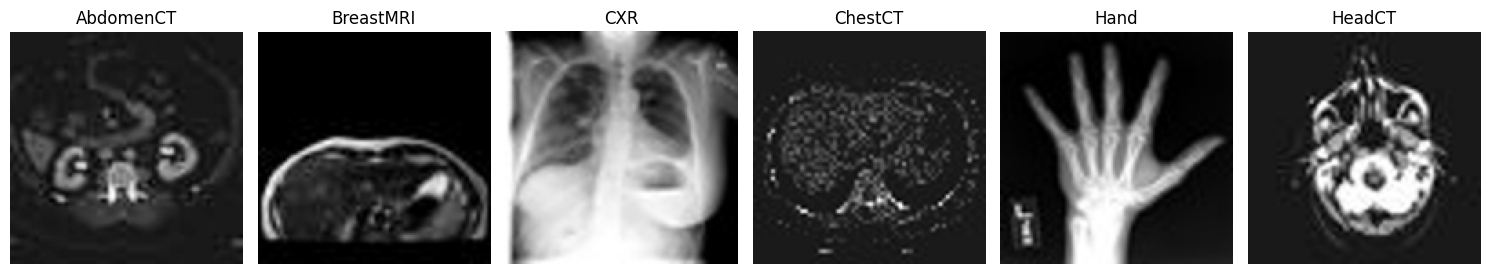

In [14]:
from sklearn.model_selection import train_test_split
from collections import Counter

IMAGE_SIZE = (128, 128)
MAX_IMAGES_PER_CLASS = 250  # Increase for stronger experiments; decrease if RAM/time is limited.
VALID_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# Find the directory whose immediate subdirectories contain image files.
root = pathlib.Path(DATASET_PATH)
candidate_dirs = []
for d in [root] + [p for p in root.rglob("*") if p.is_dir()]:
    subdirs = [p for p in d.iterdir() if p.is_dir()] if d.exists() else []
    if len(subdirs) >= 2:
        score = sum(1 for sd in subdirs for f in sd.iterdir() if f.is_file() and f.suffix.lower() in VALID_EXTS)
        if score:
            candidate_dirs.append((score, d))
if not candidate_dirs:
    raise FileNotFoundError(f"Could not find class folders containing images under {DATASET_PATH}")
DATA_ROOT = max(candidate_dirs, key=lambda x: x[0])[1]
print("Detected class-folder root:", DATA_ROOT)

image_paths, labels = [], []
for class_dir in sorted([p for p in DATA_ROOT.iterdir() if p.is_dir()]):
    files = [p for p in class_dir.rglob("*") if p.is_file() and p.suffix.lower() in VALID_EXTS]
    random.Random(SEED).shuffle(files)
    files = files[:MAX_IMAGES_PER_CLASS]
    image_paths.extend([str(p) for p in files])
    labels.extend([class_dir.name] * len(files))

if not image_paths:
    raise RuntimeError("No images found. Check the downloaded dataset folder structure.")
class_names = sorted(set(labels))
label_to_id = {name: i for i, name in enumerate(class_names)}
y = np.array([label_to_id[name] for name in labels], dtype=np.int64)

X_images = np.empty((len(image_paths), IMAGE_SIZE[1], IMAGE_SIZE[0]), dtype=np.uint8)
kept_paths, kept_y = [], []
for i, path in enumerate(image_paths):
    try:
        with Image.open(path) as im:
            X_images[i] = np.asarray(im.convert("L").resize(IMAGE_SIZE), dtype=np.uint8)
        kept_paths.append(path)
        kept_y.append(y[i])
    except Exception as e:
        print("Skipping unreadable image:", path, e)
X_images = X_images[:len(kept_y)]
y = np.asarray(kept_y, dtype=np.int64)
image_paths = kept_paths

indices = np.arange(len(y))
train_idx, temp_idx = train_test_split(indices, test_size=0.30, random_state=SEED, stratify=y)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED, stratify=y[temp_idx])

X_train_img, y_train = X_images[train_idx], y[train_idx]
X_val_img, y_val = X_images[val_idx], y[val_idx]
X_test_img, y_test = X_images[test_idx], y[test_idx]

print("Classes:", {i: name for name, i in label_to_id.items()})
print("Train:", len(y_train), "Validation:", len(y_val), "Test:", len(y_test))
print("Train class counts:", Counter(y_train))
fig, axes = plt.subplots(1, min(6, len(class_names)), figsize=(15, 3))
for ax, class_id in zip(np.atleast_1d(axes), range(min(6, len(class_names)))):
    ix = np.where(y == class_id)[0][0]
    ax.imshow(X_images[ix], cmap="gray")
    ax.set_title(class_names[class_id])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 3 — Implement the baseline HOG + SVM pipeline
The HOG parameters follow the lab specification: 9 orientations, 8 × 8 pixels per cell, 2 × 2 cells per block, L2-Hys normalization. SVM hyperparameters are chosen using validation macro-F1, not the test set.

In [15]:

from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.metrics import f1_score
import numpy as np
import time

HOG_PARAMS = {
    "orientations": 9,
    "pixels_per_cell": (8, 8),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
    "transform_sqrt": True,
    "feature_vector": True
}

task3_start = time.perf_counter()

X_train_hog = np.asarray(
    [hog(img, **HOG_PARAMS) for img in X_train_img],
    dtype=np.float32
)

X_val_hog = np.asarray(
    [hog(img, **HOG_PARAMS) for img in X_val_img],
    dtype=np.float32
)

print("Training HOG feature shape:", X_train_hog.shape)
print("Validation HOG feature shape:", X_val_hog.shape)

baseline_candidates = []

for C in [0.1, 1, 10]:
    svm = SVC(
        kernel="rbf",
        C=C,
        gamma="scale",
        class_weight="balanced",
        random_state=SEED
    )

    svm.fit(X_train_hog, y_train)

    val_predictions = svm.predict(X_val_hog)

    val_macro_f1 = f1_score(
        y_val,
        val_predictions,
        average="macro",
        zero_division=0
    )

    baseline_candidates.append({
        "C": C,
        "macro_f1": val_macro_f1,
        "model": svm
    })

    print(f"C = {C}: Validation Macro-F1 = {val_macro_f1:.4f}")

best_baseline = max(
    baseline_candidates,
    key=lambda item: item["macro_f1"]
)

baseline_model = best_baseline["model"]
baseline_C = best_baseline["C"]

task3_time = time.perf_counter() - task3_start

print("\nTask 3 completed successfully.")
print("Selected SVM C:", baseline_C)
print("Best validation Macro-F1:", round(best_baseline["macro_f1"], 4))
print(f"Total Task 3 time: {task3_time:.2f} seconds")


Training HOG feature shape: (1050, 8100)
Validation HOG feature shape: (225, 8100)
C = 0.1: Validation Macro-F1 = 0.9776
C = 1: Validation Macro-F1 = 0.9956
C = 10: Validation Macro-F1 = 0.9956

Task 3 completed successfully.
Selected SVM C: 1
Best validation Macro-F1: 0.9956
Total Task 3 time: 33.45 seconds


## Task 4 — Extract HOG features

In [16]:
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score, precision_score,
    recall_score, confusion_matrix, cohen_kappa_score, matthews_corrcoef
)
from sklearn.preprocessing import label_binarize
from sklearn.metrics import classification_report

HOG_PARAMS = dict(
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    transform_sqrt=True,
    feature_vector=True
)

t_hog_start = time.perf_counter()
X_hog = np.asarray([hog(img, **HOG_PARAMS) for img in X_images], dtype=np.float32)
hog_extraction_seconds = time.perf_counter() - t_hog_start
X_train, X_val, X_test = X_hog[train_idx], X_hog[val_idx], X_hog[test_idx]
print("HOG feature matrix:", X_hog.shape)
print("Features per image:", X_hog.shape[1])
print(f"HOG extraction time: {hog_extraction_seconds:.2f} seconds")

HOG feature matrix: (1500, 8100)
Features per image: 8100
HOG extraction time: 11.35 seconds


In [17]:
# Baseline model selection on validation macro-F1.
baseline_candidates = []
baseline_fit_start = time.perf_counter()
for C in [0.1, 1, 10]:
    model = SVC(kernel="rbf", C=C, gamma="scale", class_weight="balanced", random_state=SEED)
    fit_start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - fit_start
    val_pred = model.predict(X_val)
    score = f1_score(y_val, val_pred, average="macro", zero_division=0)
    baseline_candidates.append({"C": C, "validation_macro_f1": score, "fit_seconds": fit_seconds, "model": model})
    print(f"C={C:<4} validation macro-F1={score:.4f}, fit={fit_seconds:.2f}s")
baseline_best = max(baseline_candidates, key=lambda row: row["validation_macro_f1"])
baseline_model = baseline_best["model"]
print("Selected baseline C:", baseline_best["C"])
print("Best validation macro-F1:", round(baseline_best["validation_macro_f1"], 4))

C=0.1  validation macro-F1=0.9776, fit=7.82s
C=1    validation macro-F1=0.9956, fit=4.92s
C=10   validation macro-F1=0.9956, fit=5.38s
Selected baseline C: 1
Best validation macro-F1: 0.9956


## Task 5 — Implement the Genetic Algorithm
Each chromosome is a binary mask over HOG features. The implementation includes random population initialization, fitness evaluation, tournament selection, one-point crossover, and bit-flip mutation. Fitness uses validation macro-F1 minus a feature-count penalty, so the GA balances classification quality and compactness.

In [18]:
from sklearn.base import clone

GA_FEATURE_PENALTY = 0.05
GA_CACHE = {}

def evaluate_chromosome(mask, Xtr=X_train, ytr=y_train, Xv=X_val, yv=y_val):
    mask = np.asarray(mask, dtype=bool)
    key = np.packbits(mask).tobytes()
    if key in GA_CACHE:
        return GA_CACHE[key]
    selected = int(mask.sum())
    if selected == 0:
        fitness = -1.0
    else:
        clf = SVC(kernel="rbf", C=baseline_best["C"], gamma="scale",
                  class_weight="balanced", random_state=SEED)
        clf.fit(Xtr[:, mask], ytr)
        pred = clf.predict(Xv[:, mask])
        macro_f1 = f1_score(yv, pred, average="macro", zero_division=0)
        penalty = GA_FEATURE_PENALTY * (selected / mask.size)
        fitness = float(macro_f1 - penalty)
    GA_CACHE[key] = fitness
    return fitness

def tournament_select(population, fitnesses, rng, tournament_size=3):
    picks = rng.choice(len(population), size=min(tournament_size, len(population)), replace=False)
    winner = picks[np.argmax([fitnesses[i] for i in picks])]
    return population[winner].copy()

def run_genetic_algorithm(population_size=10, generations=6, mutation_probability=0.02, seed=SEED):
    rng = np.random.default_rng(seed)
    n_features = X_train.shape[1]
    population = (rng.random((population_size, n_features)) < 0.5)
    # Include one compact chromosome and one full-feature chromosome for diversity.
    population[0] = rng.random(n_features) < 0.25
    population[1] = True
    history = []
    best_mask, best_fitness = None, -np.inf
    for generation in range(generations):
        fitnesses = np.array([evaluate_chromosome(ch) for ch in population])
        gen_best_idx = int(np.argmax(fitnesses))
        if fitnesses[gen_best_idx] > best_fitness:
            best_fitness = float(fitnesses[gen_best_idx])
            best_mask = population[gen_best_idx].copy()
        history.append({
            "generation": generation + 1,
            "best_fitness": float(fitnesses[gen_best_idx]),
            "best_so_far_fitness": best_fitness,
            "features_selected": int(best_mask.sum())
        })
        print(f"Generation {generation+1}/{generations}: best fitness={fitnesses[gen_best_idx]:.4f}; "
              f"best-so-far={best_fitness:.4f}; features={best_mask.sum()}/{n_features}")
        next_population = [best_mask.copy()]  # elitism
        while len(next_population) < population_size:
            p1 = tournament_select(population, fitnesses, rng)
            p2 = tournament_select(population, fitnesses, rng)
            if n_features > 1 and rng.random() < 0.8:
                point = int(rng.integers(1, n_features))
                child1 = np.concatenate([p1[:point], p2[point:]])
                child2 = np.concatenate([p2[:point], p1[point:]])
            else:
                child1, child2 = p1.copy(), p2.copy()
            for child in (child1, child2):
                mutation = rng.random(n_features) < mutation_probability
                child[mutation] = ~child[mutation]
                next_population.append(child)
                if len(next_population) >= population_size:
                    break
        population = np.asarray(next_population[:population_size], dtype=bool)
    return best_mask, pd.DataFrame(history), best_fitness

## Task 6 — Select HOG features using validation macro-F1 and a feature penalty


In [19]:
ga_settings = [
    {"name": "GA-A: smaller population", "population_size": 8, "generations": 5, "mutation_probability": 0.01, "seed": SEED},
    {"name": "GA-B: higher mutation", "population_size": 10, "generations": 5, "mutation_probability": 0.05, "seed": SEED + 1},
]
ga_runs = {}
for settings in ga_settings:
    print("\n", settings["name"])
    start = time.perf_counter()
    mask, history, fitness = run_genetic_algorithm(
        population_size=settings["population_size"],
        generations=settings["generations"],
        mutation_probability=settings["mutation_probability"],
        seed=settings["seed"]
    )
    elapsed = time.perf_counter() - start
    ga_runs[settings["name"]] = {
        "settings": settings, "mask": mask, "history": history,
        "fitness": fitness, "elapsed_seconds": elapsed
    }
    print(f"Elapsed GA time: {elapsed:.2f}s; selected {mask.sum()} / {mask.size} features")
best_ga_name = max(ga_runs, key=lambda name: ga_runs[name]["fitness"])
best_ga = ga_runs[best_ga_name]
selected_mask = best_ga["mask"]
print("\nSelected GA configuration:", best_ga_name)
print("Selected validation fitness:", round(best_ga["fitness"], 4))
print("Selected feature count:", int(selected_mask.sum()))


 GA-A: smaller population
Generation 1/5: best fitness=0.9829; best-so-far=0.9829; features=2044/8100
Generation 2/5: best fitness=0.9829; best-so-far=0.9829; features=2044/8100
Generation 3/5: best fitness=0.9829; best-so-far=0.9829; features=2044/8100
Generation 4/5: best fitness=0.9829; best-so-far=0.9829; features=2044/8100
Generation 5/5: best fitness=0.9829; best-so-far=0.9829; features=2044/8100
Elapsed GA time: 72.36s; selected 2044 / 8100 features

 GA-B: higher mutation
Generation 1/5: best fitness=0.9830; best-so-far=0.9830; features=2028/8100
Generation 2/5: best fitness=0.9830; best-so-far=0.9830; features=2028/8100
Generation 3/5: best fitness=0.9830; best-so-far=0.9830; features=2028/8100
Generation 4/5: best fitness=0.9830; best-so-far=0.9830; features=2028/8100
Generation 5/5: best fitness=0.9830; best-so-far=0.9830; features=2028/8100
Elapsed GA time: 77.29s; selected 2028 / 8100 features

Selected GA configuration: GA-B: higher mutation
Selected validation fitness: 

## Task 7 — Train an SVM using the selected features
The final GA-HOG SVM is fitted on the training split using the GA-selected feature subset. The test set is evaluated only after the validation-based feature selection and configuration choice are complete.

In [20]:
if selected_mask.sum() == 0:
    raise RuntimeError("GA selected zero features; rerun with a larger population or more generations.")
ga_model = SVC(kernel="rbf", C=baseline_best["C"], gamma="scale",
                class_weight="balanced", random_state=SEED)
ga_fit_start = time.perf_counter()
ga_model.fit(X_train[:, selected_mask], y_train)
ga_fit_seconds = time.perf_counter() - ga_fit_start
print("GA-HOG SVM fitted.")
print("Features used:", int(selected_mask.sum()), "of", X_train.shape[1])
print(f"Final GA-HOG SVM training time: {ga_fit_seconds:.2f} seconds")

GA-HOG SVM fitted.
Features used: 2028 of 8100
Final GA-HOG SVM training time: 0.86 seconds


## Task 8 — Compare baseline and GA-HOG models
The following cell performs the final test evaluation for both locked models and reports accuracy, macro-F1, balanced accuracy, macro precision/recall, weighted-F1, macro specificity, Cohen's kappa, Matthews correlation coefficient, and elapsed prediction/evaluation time. These are actual measurements from the current notebook run, not pre-filled example values.

In [21]:
def macro_specificity(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    specs = []
    total = cm.sum()
    for i in range(len(labels)):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp
        denom = tn + fp
        specs.append(tn / denom if denom else 0.0)
    return float(np.mean(specs))

all_labels = np.arange(len(class_names))
results = []
predictions = {}
for name, model, use_mask in [
    ("HOG + SVM (Baseline)", baseline_model, None),
    (f"GA-HOG + SVM ({best_ga_name})", ga_model, selected_mask)
]:
    start = time.perf_counter()
    test_features = X_test if use_mask is None else X_test[:, use_mask]
    pred = model.predict(test_features)
    eval_seconds = time.perf_counter() - start
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy (%)": 100 * accuracy_score(y_test, pred),
        "Precision Macro (%)": 100 * precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall Macro (%)": 100 * recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro-F1 (%)": 100 * f1_score(y_test, pred, average="macro", zero_division=0),
        "Weighted-F1 (%)": 100 * f1_score(y_test, pred, average="weighted", zero_division=0),
        "Balanced Accuracy (%)": 100 * balanced_accuracy_score(y_test, pred),
        "Specificity Macro (%)": 100 * macro_specificity(y_test, pred, all_labels),
        "Cohen Kappa": cohen_kappa_score(y_test, pred),
        "Matthews Corrcoef": matthews_corrcoef(y_test, pred),
        "Test prediction time (s)": eval_seconds
    })
results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))
print("\nClassification report — baseline")
print(classification_report(y_test, predictions["HOG + SVM (Baseline)"], target_names=class_names, zero_division=0))
print("\nClassification report — GA-HOG")
print(classification_report(y_test, predictions[f"GA-HOG + SVM ({best_ga_name})"], target_names=class_names, zero_division=0))

,Accuracy (%),Precision Macro (%),Recall Macro (%),Macro-F1 (%),Weighted-F1 (%),Balanced Accuracy (%),Specificity Macro (%),Cohen Kappa,Matthews Corrcoef,Test prediction time (s)
Model,,,,,,,,,,
HOG + SVM (Baseline),100.0,100.0,100.0,100.0,100.0,100.0,100.0,1.0,1.0,1.7123
GA-HOG + SVM (GA-B: higher mutation),100.0,100.0,100.0,100.0,100.0,100.0,100.0,1.0,1.0,0.3046



Classification report — baseline
              precision    recall  f1-score   support

   AbdomenCT       1.00      1.00      1.00        37
   BreastMRI       1.00      1.00      1.00        37
         CXR       1.00      1.00      1.00        38
     ChestCT       1.00      1.00      1.00        38
        Hand       1.00      1.00      1.00        38
      HeadCT       1.00      1.00      1.00        37

    accuracy                           1.00       225
   macro avg       1.00      1.00      1.00       225
weighted avg       1.00      1.00      1.00       225


Classification report — GA-HOG
              precision    recall  f1-score   support

   AbdomenCT       1.00      1.00      1.00        37
   BreastMRI       1.00      1.00      1.00        37
         CXR       1.00      1.00      1.00        38
     ChestCT       1.00      1.00      1.00        38
        Hand       1.00      1.00      1.00        38
      HeadCT       1.00      1.00      1.00        37

    accurac

## Task 9 — Plot GA fitness and feature dimensionality before/after selection
Plots show best fitness across generations for both GA settings and the reduction in the number of HOG features. The experiment tables are also exported as CSV files for submission.

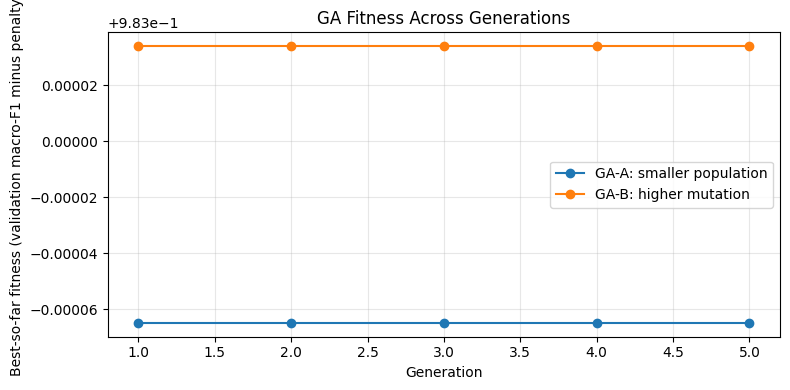

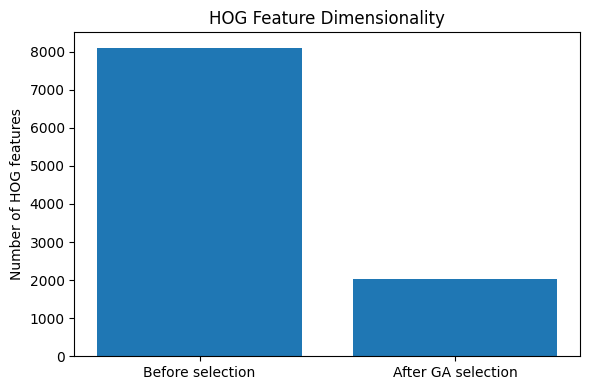

,Stage,Number of features
0,Before selection,8100
1,After GA selection,2028


,Accuracy (%),Precision Macro (%),Recall Macro (%),Macro-F1 (%),Weighted-F1 (%),Balanced Accuracy (%),Specificity Macro (%),Cohen Kappa,Matthews Corrcoef,Test prediction time (s),Features used,GA search time (s)
Model,,,,,,,,,,,,
HOG + SVM (Baseline),100.0,100.0,100.0,100.0,100.0,100.0,100.0,1.0,1.0,1.7123,8100,0.000
GA-HOG + SVM (GA-B: higher mutation),100.0,100.0,100.0,100.0,100.0,100.0,100.0,1.0,1.0,0.3046,2028,77.293


Saved result CSV files to the current notebook directory.


In [22]:
plt.figure(figsize=(8, 4))
for name, run in ga_runs.items():
    plt.plot(run["history"]["generation"], run["history"]["best_so_far_fitness"], marker="o", label=name)
plt.xlabel("Generation")
plt.ylabel("Best-so-far fitness (validation macro-F1 minus penalty)")
plt.title("GA Fitness Across Generations")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

feature_counts = pd.DataFrame({
    "Stage": ["Before selection", "After GA selection"],
    "Number of features": [X_train.shape[1], int(selected_mask.sum())]
})
plt.figure(figsize=(6, 4))
plt.bar(feature_counts["Stage"], feature_counts["Number of features"])
plt.ylabel("Number of HOG features")
plt.title("HOG Feature Dimensionality")
plt.tight_layout()
plt.show()

display(feature_counts)
comparison = results_df.copy()
comparison["Features used"] = [X_train.shape[1], int(selected_mask.sum())]
comparison["GA search time (s)"] = [0.0, best_ga["elapsed_seconds"]]
display(comparison.round(4))

results_df.to_csv("lab07_test_results.csv")
feature_counts.to_csv("lab07_feature_counts.csv", index=False)
for name, run in ga_runs.items():
    run["history"].to_csv("lab07_" + name.lower().replace(" ", "_").replace(":", "") + "_fitness.csv", index=False)
print("Saved result CSV files to the current notebook directory.")

## Task 10 — Discuss strengths, limitations, and computational cost
Use the measured results above to write the discussion. The cell below generates a short evidence-based summary from this run. Interpret a performance change as an improvement only if the corresponding test metric is higher; feature reduction alone does not guarantee better classification.

In [23]:
baseline_row = results_df.loc["HOG + SVM (Baseline)"]
ga_row = results_df.loc[f"GA-HOG + SVM ({best_ga_name})"]
reduction_pct = 100 * (1 - selected_mask.sum() / X_train.shape[1])
f1_change = ga_row["Macro-F1 (%)"] - baseline_row["Macro-F1 (%)"]
acc_change = ga_row["Accuracy (%)"] - baseline_row["Accuracy (%)"]

print("SHORT REPORT — LAB 07")
print("=" * 60)
print(f"Dataset: Kaggle Medical MNIST; classes: {', '.join(class_names)}.")
print(f"Images used: {len(y)}; fixed split sizes: train={len(y_train)}, validation={len(y_val)}, test={len(y_test)}.")
print(f"HOG feature dimensionality: {X_train.shape[1]} before selection, {selected_mask.sum()} after selection "
      f"({reduction_pct:.2f}% reduction).")
print(f"Baseline test accuracy: {baseline_row['Accuracy (%)']:.2f}%; macro-F1: {baseline_row['Macro-F1 (%)']:.2f}%.")
print(f"GA-HOG test accuracy: {ga_row['Accuracy (%)']:.2f}%; macro-F1: {ga_row['Macro-F1 (%)']:.2f}%.")
print(f"Change in test accuracy: {acc_change:+.2f} percentage points; change in macro-F1: {f1_change:+.2f} percentage points.")
print(f"GA configuration selected on validation fitness: {best_ga_name}; GA search time: {best_ga['elapsed_seconds']:.2f}s.")
print("\nStrengths:")
print("- The GA searches for a compact subset of HOG features using validation macro-F1.")
print("- Identical fixed splits make the baseline and proposed model comparison fair.")
print("- Multiple GA settings and multiple classification metrics are reported.")
print("\nLimitations and computational cost:")
print("- GA fitness evaluation repeatedly trains SVMs and can be much slower than fitting one baseline model.")
print("- Results depend on random seed, population size, generations, mutation rate, feature penalty, and sample cap.")
print("- The per-class sample cap makes this run faster but results may differ when trained on the full dataset.")
print("- HOG uses hand-crafted gradients and may not capture all medical-image semantics.")
print("\nConclusion:")
if f1_change > 0:
    print("GA-HOG improved test macro-F1 in this run; consider the gain alongside feature reduction and GA runtime.")
elif f1_change < 0:
    print("GA-HOG did not improve test macro-F1 in this run, although it may still reduce dimensionality.")
else:
    print("GA-HOG matched baseline test macro-F1 in this run; evaluate whether feature reduction justifies added runtime.")
print("Use these printed measurements and the generated tables/plots in the submitted report.")

SHORT REPORT — LAB 07
Dataset: Kaggle Medical MNIST; classes: AbdomenCT, BreastMRI, CXR, ChestCT, Hand, HeadCT.
Images used: 1500; fixed split sizes: train=1050, validation=225, test=225.
HOG feature dimensionality: 8100 before selection, 2028 after selection (74.96% reduction).
Baseline test accuracy: 100.00%; macro-F1: 100.00%.
GA-HOG test accuracy: 100.00%; macro-F1: 100.00%.
Change in test accuracy: +0.00 percentage points; change in macro-F1: +0.00 percentage points.
GA configuration selected on validation fitness: GA-B: higher mutation; GA search time: 77.29s.

Strengths:
- The GA searches for a compact subset of HOG features using validation macro-F1.
- Identical fixed splits make the baseline and proposed model comparison fair.
- Multiple GA settings and multiple classification metrics are reported.

Limitations and computational cost:
- GA fitness evaluation repeatedly trains SVMs and can be much slower than fitting one baseline model.
- Results depend on random seed, populati

## Reproducibility notes and submission checklist
- Dataset reference: https://www.kaggle.com/datasets/andrewmvd/medical-mnist
- Image resolution: 128 × 128 grayscale.
- HOG: 9 orientations, 8 × 8 pixels per cell, 2 × 2 cells per block, L2-Hys.
- Classifier: RBF-kernel SVM; C selected using validation macro-F1.
- GA settings compared: population size and mutation probability differ between the two runs.
- All methods use the same fixed train/validation/test indices.
- Test metrics are calculated only after selecting the GA configuration on validation fitness.
- Exported files: `lab07_test_results.csv`, `lab07_feature_counts.csv`, and GA fitness history CSV files.

**Important:** Report only the experimental values generated by your own run. Runtime and scores depend on the dataset contents, software versions, and available hardware.